In [2]:
# --- Cell 1: Imports ---
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import linregress
from matplotlib.font_manager import FontProperties

In [3]:
 def fractional_years(time_index):
    dt = pd.to_datetime(time_index)
    year = dt.year
    start = pd.to_datetime(year.astype(str) + "-01-01")
    end = pd.to_datetime((year+1).astype(str) + "-01-01")
    frac = (dt - start) / (end - start)
    return (year + frac.values).to_numpy()

def poly_harmonic(t, *params):
    order_poly = 3
    n_harm = 4
    poly = sum(params[i] * (t - t.mean())**i for i in range(order_poly+1))
    harmonics = sum(
        params[order_poly+1+2*(k-1)]*np.sin(2*np.pi*k*t) +
        params[order_poly+2*k]*np.cos(2*np.pi*k*t)
        for k in range(1, n_harm+1)
    )
    return poly + harmonics

def fit_model(t, y):
    order_poly, n_harm = 3, 4
    n_params = (order_poly+1) + 2*n_harm
    p0 = np.zeros(n_params)
    popt, _ = curve_fit(poly_harmonic, t, y, p0=p0, maxfev=10000)
    return popt

In [4]:
def compute_yearly_amplitudes(time, y, order_poly=3, n_harm=4):
    """
    Compute yearly seasonal amplitudes (max - min) using 
    polynomial + harmonic fit with ±1 yr window (edges use 3 years).
    Also returns the smoothed fitted series for the full timeseries.

    Parameters
    ----------
    time : pandas.DatetimeIndex
        Time array (monthly or daily).
    y : array-like
        Timeseries values (same length as time).
    order_poly : int, optional
        Polynomial order (default=3).
    n_harm : int, optional
        Number of harmonics (default=4).

    Returns
    -------
    years : np.ndarray
        Array of years.
    amplitudes : np.ndarray
        Yearly amplitudes (max - min).
    y_smooth : np.ndarray
        Smoothed fitted timeseries (same length as time).
    """
    t_years = fractional_years(time)
    y = np.asarray(y)

    years = np.arange(time.year.min(), time.year.max()+1)
    amplitudes = []
    y_smooth = np.full_like(y, np.nan, dtype=float)  # init smoothed series

    for yr in years:
        if yr == time.year.min():  
            mask = (time.year >= yr) & (time.year <= yr+2)
        elif yr == time.year.max():
            mask = (time.year >= yr-2) & (time.year <= yr)
        else:
            mask = (time.year >= yr-1) & (time.year <= yr+1)

        if mask.sum() < 6:
            amplitudes.append(np.nan)
            continue

        t_sub = t_years[mask]
        y_sub = y[mask]

        # local fit
        popt_sub = fit_model(t_sub, y_sub)
        y_model = poly_harmonic(t_sub, *popt_sub)

        # store smoothed values for this year's indices
        y_smooth[mask] = y_model  

        # compute amplitude only for this year
        df = pd.DataFrame({"t": t_sub, "y": y_model, "date": time[mask]})
        df["year"] = df["date"].dt.year
        y_this_year = df[df["year"] == yr]["y"]

        if len(y_this_year) == 0:
            amplitudes.append(np.nan)
        else:
            amplitudes.append(y_this_year.max() - y_this_year.min())

    return years, np.array(amplitudes), time, y_smooth



In [5]:
# --- Cell 2: Load data and make timeseries ---
# Replace "your_file.nc" and "pco2" with actual file and variable names
ds = xr.open_dataset("pCO2-Corrected_INCOIS-BIO-ROMS.nc")
pco2 = ds["pCO2_Clim"]  # shape: (TIME, LAT, LON)
temp = ds["SST"]
dev = ds["Deviant_uncertainty"]

# Average over lat & lon -> 1D timeseries
time = pd.to_datetime(pco2["TIME"].values)
# Arabian Sea
pco2_AS = pco2.sel(LON=slice(30,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])
temp_AS = temp.sel(LON=slice(30,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])
dev_AS = dev.sel(LON=slice(30,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])
# Eastern Arabian Sea
pco2_EAS = pco2.sel(LON=slice(30,65),LAT=slice(0,30)).mean(dim=['LAT','LON'])
temp_EAS = temp.sel(LON=slice(30,65),LAT=slice(0,30)).mean(dim=['LAT','LON'])
dev_EAS = dev.sel(LON=slice(30,65),LAT=slice(0,30)).mean(dim=['LAT','LON'])
# Western Arabian Sea
pco2_WAS = pco2.sel(LON=slice(65,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])
temp_WAS = temp.sel(LON=slice(65,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])
dev_WAS = dev.sel(LON=slice(65,78),LAT=slice(0,30)).mean(dim=['LAT','LON'])
# Bay of Bengal
pco2_BoB = pco2.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['LAT','LON'])
temp_BoB = temp.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['LAT','LON'])
dev_BoB = dev.sel(LON=slice(78,110),LAT=slice(0,30)).mean(dim=['LAT','LON'])
# North Bay of Bengal
pco2_NBoB = pco2.sel(LON=slice(78,110),LAT=slice(15,30)).mean(dim=['LAT','LON'])
temp_NBoB = temp.sel(LON=slice(78,110),LAT=slice(15,30)).mean(dim=['LAT','LON'])
dev_NBoB = dev.sel(LON=slice(78,110),LAT=slice(15,30)).mean(dim=['LAT','LON'])
# South Bay of Bengal
pco2_SBoB = pco2.sel(LON=slice(78,110),LAT=slice(0,15)).mean(dim=['LAT','LON'])
temp_SBoB = temp.sel(LON=slice(78,110),LAT=slice(0,15)).mean(dim=['LAT','LON'])
dev_SBoB = dev.sel(LON=slice(78,110),LAT=slice(0,15)).mean(dim=['LAT','LON'])
# Equatorial Indian Ocean
pco2_EIO = pco2.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['LAT','LON'])
temp_EIO = temp.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['LAT','LON'])
dev_EIO = dev.sel(LON=slice(30,120),LAT=slice(-18,0)).mean(dim=['LAT','LON'])
# Southern Indian Ocean
pco2_SIO = pco2.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
temp_SIO = temp.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])
dev_SIO = dev.sel(LON=slice(30,120),LAT=slice(-30,-18)).mean(dim=['LAT','LON'])


print(pco2_AS.shape, temp_AS.shape)


(480,) (480,)


# AS

In [6]:
years, amplitudes1AS, time, y_smooth1AS = compute_yearly_amplitudes(time, pco2_AS.values)
years, amplitudes2AS, time, y_smooth2AS = compute_yearly_amplitudes(time, temp_AS.values)
years, amplitudes3AS, time, y_smooth3AS = compute_yearly_amplitudes(time, dev_AS.values)

In [7]:
pco2_AS = xr.DataArray(
    y_smooth1AS,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_AS"
)

temp_AS = xr.DataArray(
    y_smooth2AS,
    coords={"TIME": time},
    dims=["TIME"],
    name="temp_AS"
)

dev_AS = xr.DataArray(
    y_smooth3AS,
    coords={"TIME": time},
    dims=["TIME"],
    name="dev_AS"
)


# EAS

In [8]:
years, amplitudes1EAS, time, y_smooth1EAS = compute_yearly_amplitudes(time, pco2_EAS.values)
years, amplitudes2EAS, time, y_smooth2EAS = compute_yearly_amplitudes(time, temp_EAS.values)
years, amplitudes3EAS, time, y_smooth3EAS = compute_yearly_amplitudes(time, dev_EAS.values)

In [9]:
pco2_EAS = xr.DataArray(
    y_smooth1EAS,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_EAS"
)

temp_EAS = xr.DataArray(
    y_smooth2EAS,
    coords={"TIME": time},
    dims=["TIME"],
    name="temp_EAS"
)

dev_EAS = xr.DataArray(
    y_smooth3EAS,
    coords={"TIME": time},
    dims=["TIME"],
    name="dev_EAS"
)


# WAS

In [10]:
years, amplitudes1WAS, time, y_smooth1WAS = compute_yearly_amplitudes(time, pco2_WAS.values)
years, amplitudes2WAS, time, y_smooth2WAS = compute_yearly_amplitudes(time, temp_WAS.values)
years, amplitudes3WAS, time, y_smooth3WAS = compute_yearly_amplitudes(time, dev_WAS.values)

In [11]:
pco2_WAS = xr.DataArray(
    y_smooth1WAS,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_WAS"
)

temp_WAS = xr.DataArray(
    y_smooth2WAS,
    coords={"TIME": time},
    dims=["TIME"],
    name="temp_WAS"
)

dev_WAS = xr.DataArray(
    y_smooth3WAS,
    coords={"TIME": time},
    dims=["TIME"],
    name="dev_WAS"
)


# BoB

In [12]:
years, amplitudes1BoB, time, y_smooth1BoB = compute_yearly_amplitudes(time, pco2_BoB.values)
years, amplitudes2BoB, time, y_smooth2BoB = compute_yearly_amplitudes(time, temp_BoB.values)
years, amplitudes3BoB, time, y_smooth3BoB = compute_yearly_amplitudes(time, dev_BoB.values)

In [13]:
pco2_BoB = xr.DataArray(
    y_smooth1BoB,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_BoB"
)

temp_BoB = xr.DataArray(
    y_smooth2BoB,
    coords={"TIME": time},
    dims=["TIME"],
    name="temp_BoB"
)

dev_BoB = xr.DataArray(
    y_smooth3BoB,
    coords={"TIME": time},
    dims=["TIME"],
    name="dev_BoB"
)


# NBoB

In [14]:
years, amplitudes1NBoB, time, y_smooth1NBoB = compute_yearly_amplitudes(time, pco2_NBoB.values)
years, amplitudes2NBoB, time, y_smooth2NBoB = compute_yearly_amplitudes(time, temp_NBoB.values)
years, amplitudes3NBoB, time, y_smooth3NBoB = compute_yearly_amplitudes(time, dev_NBoB.values)

In [15]:
pco2_NBoB = xr.DataArray(
    y_smooth1NBoB,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_NBoB"
)

temp_NBoB = xr.DataArray(
    y_smooth2NBoB,
    coords={"TIME": time},
    dims=["TIME"],
    name="temp_NBoB"
)

dev_NBoB = xr.DataArray(
    y_smooth3NBoB,
    coords={"TIME": time},
    dims=["TIME"],
    name="dev_NBoB"
)


# SBoB

In [16]:
years, amplitudes1SBoB, time, y_smooth1SBoB = compute_yearly_amplitudes(time, pco2_SBoB.values)
years, amplitudes2SBoB, time, y_smooth2SBoB = compute_yearly_amplitudes(time, temp_SBoB.values)
years, amplitudes3SBoB, time, y_smooth3SBoB = compute_yearly_amplitudes(time, dev_SBoB.values)

In [17]:
pco2_SBoB = xr.DataArray(
    y_smooth1SBoB,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_SBoB"
)

temp_SBoB = xr.DataArray(
    y_smooth2SBoB,
    coords={"TIME": time},
    dims=["TIME"],
    name="temp_SBoB"
)

dev_SBoB = xr.DataArray(
    y_smooth3SBoB,
    coords={"TIME": time},
    dims=["TIME"],
    name="dev_SBoB"
)


# EIO

In [18]:
years, amplitudes1EIO, time, y_smooth1EIO = compute_yearly_amplitudes(time, pco2_EIO.values)
years, amplitudes2EIO, time, y_smooth2EIO = compute_yearly_amplitudes(time, temp_EIO.values)
years, amplitudes3EIO, time, y_smooth3EIO = compute_yearly_amplitudes(time, dev_EIO.values)

In [19]:
pco2_EIO = xr.DataArray(
    y_smooth1EIO,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_EIO"
)

temp_EIO = xr.DataArray(
    y_smooth2EIO,
    coords={"TIME": time},
    dims=["TIME"],
    name="temp_EIO"
)

dev_EIO = xr.DataArray(
    y_smooth3EIO,
    coords={"TIME": time},
    dims=["TIME"],
    name="dev_EIO"
)


# SIO

In [20]:
years, amplitudes1SIO, time, y_smooth1SIO = compute_yearly_amplitudes(time, pco2_SIO.values)
years, amplitudes2SIO, time, y_smooth2SIO = compute_yearly_amplitudes(time, temp_SIO.values)
years, amplitudes3SIO, time, y_smooth3SIO = compute_yearly_amplitudes(time, dev_SIO.values)

In [21]:
pco2_SIO = xr.DataArray(
    y_smooth1SIO,
    coords={"TIME": time},
    dims=["TIME"],
    name="pco2_SIO"
)

temp_SIO = xr.DataArray(
    y_smooth2SIO,
    coords={"TIME": time},
    dims=["TIME"],
    name="temp_SIO"
)

dev_SIO = xr.DataArray(
    y_smooth3SIO,
    coords={"TIME": time},
    dims=["TIME"],
    name="dev_SIO"
)


# Seasonal

## AS 

In [40]:
pco2_AS_8089 = pco2_AS.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
pco2_AS_1019 = pco2_AS.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [41]:
temp_AS_8089 = temp_AS.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
temp_AS_1019 = temp_AS.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [42]:
dev_AS_8089 = dev_AS.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
dev_AS_1019 = dev_AS.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [43]:
AS_thermal_8089 = pco2_AS_8089.mean()*np.exp(0.0423*(temp_AS_8089 - temp_AS_8089.mean()))
AS_bp_8089 = pco2_AS_8089*np.exp(0.0423*(temp_AS_8089.mean() - temp_AS_8089))

In [44]:
dev_AS_thermal_8089 = dev_AS_8089.mean()*np.exp(0.0423*(temp_AS_8089 - temp_AS_8089.mean()))
dev_AS_bp_8089 = dev_AS_8089*np.exp(0.0423*(temp_AS_8089.mean() - temp_AS_8089))

In [45]:
AS_thermal_1019 = pco2_AS_1019.mean()*np.exp(0.0423*(temp_AS_1019 - temp_AS_1019.mean()))
AS_bp_1019 = pco2_AS_1019*np.exp(0.0423*(temp_AS_1019.mean() - temp_AS_1019))

In [46]:
dev_AS_thermal_1019 = dev_AS_1019.mean()*np.exp(0.0423*(temp_AS_1019 - temp_AS_1019.mean()))
dev_AS_bp_1019 = dev_AS_1019*np.exp(0.0423*(temp_AS_1019.mean() - temp_AS_1019))

In [47]:
sea_AS_8089 = pco2_AS_8089 - pco2_AS_8089.mean()
sea_AS_1019 = pco2_AS_1019 - pco2_AS_1019.mean()

In [48]:
dev_sea_AS_8089 = dev_AS_8089 - dev_AS_8089.mean()
dev_sea_AS_1019 = dev_AS_1019 - dev_AS_1019.mean()

In [49]:
sea_AS_thermal_8089 = AS_thermal_8089 - AS_thermal_8089.mean()
sea_AS_thermal_1019 = AS_thermal_1019 - AS_thermal_1019.mean()

In [50]:
dev_sea_AS_thermal_8089 = dev_AS_thermal_8089 - dev_AS_thermal_8089.mean()
dev_sea_AS_thermal_1019 = dev_AS_thermal_1019 - dev_AS_thermal_1019.mean()

In [51]:
sea_AS_bp_8089 = AS_bp_8089 - AS_bp_8089.mean()
sea_AS_bp_1019 = AS_bp_1019 - AS_bp_1019.mean()

In [52]:
dev_sea_AS_bp_8089 = dev_AS_bp_8089 - dev_AS_bp_8089.mean()
dev_sea_AS_bp_1019 = dev_AS_bp_1019 - dev_AS_bp_1019.mean()

In [53]:
A_AS_8089 = sea_AS_8089.max() - sea_AS_8089.min()
A_AS_1019 = sea_AS_1019.max() - sea_AS_1019.min()

dev_A_AS_8089 = dev_sea_AS_8089.max() - dev_sea_AS_8089.min()
dev_A_AS_1019 = dev_sea_AS_1019.max() - dev_sea_AS_1019.min()

A_inc_AS = A_AS_1019 - A_AS_8089
dev_inc_AS = dev_A_AS_1019 - dev_A_AS_8089

print(
    f"A_AS_8089: {A_AS_8089:.2f}\u00B1{dev_A_AS_8089:.2f} µatm \n"
    f"A_AS_1019: {A_AS_1019:.2f}\u00B1{dev_A_AS_1019:.2f} µatm \n"
    f"Increment_amp_AS: {A_inc_AS:.2f}\u00B1{dev_inc_AS:.2f} µatm \n"

)

A_AS_8089: 22.81±1.24 µatm 
A_AS_1019: 25.71±1.70 µatm 
Increment_amp_AS: 2.90±0.47 µatm 



In [54]:
A_AS_thermal_8089 = sea_AS_thermal_8089.max() - sea_AS_thermal_8089.min()
A_AS_thermal_1019 = sea_AS_thermal_1019.max() - sea_AS_thermal_1019.min()

dev_A_AS_thermal_8089 = dev_sea_AS_thermal_8089.max() - dev_sea_AS_thermal_8089.min()
dev_A_AS_thermal_1019 = dev_sea_AS_thermal_1019.max() - dev_sea_AS_thermal_1019.min()

A_th_inc_AS = A_AS_thermal_1019 - A_AS_thermal_8089
dev_th_inc_AS = dev_A_AS_thermal_1019 - dev_A_AS_thermal_8089

print(
    f"A_AS_thermal_8089: {A_AS_thermal_8089:.2f}\u00B1{dev_A_AS_thermal_8089:.2f} µatm \n"
    f"A_AS_thermal_1019: {A_AS_thermal_1019:.2f}\u00B1{dev_A_AS_thermal_1019:.2f} µatm \n"
    f"Increment_amp_AS: {A_th_inc_AS:.2f}\u00B1{dev_th_inc_AS:.2f} µatm \n"

)

A_AS_thermal_8089: 48.26±0.44 µatm 
A_AS_thermal_1019: 56.81±0.41 µatm 
Increment_amp_AS: 8.55±-0.03 µatm 



In [55]:
A_AS_bp_8089 = sea_AS_bp_8089.max() - sea_AS_bp_8089.min()
A_AS_bp_1019 = sea_AS_bp_1019.max() - sea_AS_bp_1019.min()

dev_A_AS_bp_8089 = dev_sea_AS_bp_8089.max() - dev_sea_AS_bp_8089.min()
dev_A_AS_bp_1019 = dev_sea_AS_bp_1019.max() - dev_sea_AS_bp_1019.min()

A_bp_inc_AS = A_AS_bp_1019 - A_AS_bp_8089
dev_bp_inc_AS = dev_A_AS_bp_1019 - dev_A_AS_bp_8089

print(
    f"A_AS_bp_8089: {A_AS_bp_8089:.2f}\u00B1{dev_A_AS_bp_8089:.2f} µatm \n"
    f"A_AS_bp_1019: {A_AS_bp_1019:.2f}\u00B1{dev_A_AS_bp_1019:.2f} µatm \n"
    f"Increment_amp_AS: {A_bp_inc_AS:.2f}\u00B1{dev_bp_inc_AS:.2f} µatm \n"

)

A_AS_bp_8089: 41.96±1.29 µatm 
A_AS_bp_1019: 39.09±1.71 µatm 
Increment_amp_AS: -2.87±0.42 µatm 



## EAS 

In [56]:
pco2_EAS_8089 = pco2_EAS.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
pco2_EAS_1019 = pco2_EAS.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [57]:
temp_EAS_8089 = temp_EAS.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
temp_EAS_1019 = temp_EAS.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [58]:
dev_EAS_8089 = dev_EAS.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
dev_EAS_1019 = dev_EAS.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [59]:
EAS_thermal_8089 = pco2_EAS_8089.mean()*np.exp(0.0423*(temp_EAS_8089 - temp_EAS_8089.mean()))
EAS_bp_8089 = pco2_EAS_8089*np.exp(0.0423*(temp_EAS_8089.mean() - temp_EAS_8089))

In [60]:
dev_EAS_thermal_8089 = dev_EAS_8089.mean()*np.exp(0.0423*(temp_EAS_8089 - temp_EAS_8089.mean()))
dev_EAS_bp_8089 = dev_EAS_8089*np.exp(0.0423*(temp_EAS_8089.mean() - temp_EAS_8089))

In [61]:
EAS_thermal_1019 = pco2_EAS_1019.mean()*np.exp(0.0423*(temp_EAS_1019 - temp_EAS_1019.mean()))
EAS_bp_1019 = pco2_EAS_1019*np.exp(0.0423*(temp_EAS_1019.mean() - temp_EAS_1019))

In [62]:
dev_EAS_thermal_1019 = dev_EAS_1019.mean()*np.exp(0.0423*(temp_EAS_1019 - temp_EAS_1019.mean()))
dev_EAS_bp_1019 = dev_EAS_1019*np.exp(0.0423*(temp_EAS_1019.mean() - temp_EAS_1019))

In [63]:
sea_EAS_8089 = pco2_EAS_8089 - pco2_EAS_8089.mean()
sea_EAS_1019 = pco2_EAS_1019 - pco2_EAS_1019.mean()

In [64]:
dev_sea_EAS_8089 = dev_EAS_8089 - dev_EAS_8089.mean()
dev_sea_EAS_1019 = dev_EAS_1019 - dev_EAS_1019.mean()

In [65]:
sea_EAS_thermal_8089 = EAS_thermal_8089 - EAS_thermal_8089.mean()
sea_EAS_thermal_1019 = EAS_thermal_1019 - EAS_thermal_1019.mean()

In [66]:
dev_sea_EAS_thermal_8089 = dev_EAS_thermal_8089 - dev_EAS_thermal_8089.mean()
dev_sea_EAS_thermal_1019 = dev_EAS_thermal_1019 - dev_EAS_thermal_1019.mean()

In [67]:
sea_EAS_bp_8089 = EAS_bp_8089 - AS_bp_8089.mean()
sea_EAS_bp_1019 = EAS_bp_1019 - EAS_bp_1019.mean()

In [68]:
dev_sea_EAS_bp_8089 = dev_EAS_bp_8089 - dev_EAS_bp_8089.mean()
dev_sea_EAS_bp_1019 = dev_EAS_bp_1019 - dev_EAS_bp_1019.mean()

In [69]:
A_EAS_8089 = sea_EAS_8089.max() - sea_EAS_8089.min()
A_EAS_1019 = sea_EAS_1019.max() - sea_EAS_1019.min()

dev_A_EAS_8089 = dev_sea_EAS_8089.max() - dev_sea_EAS_8089.min()
dev_A_EAS_1019 = dev_sea_EAS_1019.max() - dev_sea_EAS_1019.min()

A_inc_EAS = A_EAS_1019 - A_EAS_8089
dev_inc_EAS = dev_A_EAS_1019 - dev_A_EAS_8089

print(
    f"A_EAS_8089: {A_EAS_8089:.2f}\u00B1{dev_A_EAS_8089:.2f} µatm \n"
    f"A_EAS_1019: {A_EAS_1019:.2f}\u00B1{dev_A_EAS_1019:.2f} µatm \n"
    f"Increment_amp_EAS: {A_inc_EAS:.2f}\u00B1{dev_inc_EAS:.2f} µatm \n"

)

A_EAS_8089: 24.14±1.48 µatm 
A_EAS_1019: 28.78±2.09 µatm 
Increment_amp_EAS: 4.65±0.61 µatm 



In [70]:
A_EAS_thermal_8089 = sea_EAS_thermal_8089.max() - sea_EAS_thermal_8089.min()
A_EAS_thermal_1019 = sea_EAS_thermal_1019.max() - sea_EAS_thermal_1019.min()

dev_A_EAS_thermal_8089 = dev_sea_EAS_thermal_8089.max() - dev_sea_EAS_thermal_8089.min()
dev_A_EAS_thermal_1019 = dev_sea_EAS_thermal_1019.max() - dev_sea_EAS_thermal_1019.min()

A_th_inc_EAS = A_EAS_thermal_1019 - A_EAS_thermal_8089
dev_th_inc_EAS = dev_A_EAS_thermal_1019 - dev_A_EAS_thermal_8089

print(
    f"A_EAS_thermal_8089: {A_EAS_thermal_8089:.2f}\u00B1{dev_A_EAS_thermal_8089:.2f} µatm \n"
    f"A_EAS_thermal_1019: {A_EAS_thermal_1019:.2f}\u00B1{dev_A_EAS_thermal_1019:.2f} µatm \n"
    f"Increment_amp_EAS: {A_th_inc_EAS:.2f}\u00B1{dev_th_inc_EAS:.2f} µatm \n"

)

A_EAS_thermal_8089: 56.64±0.52 µatm 
A_EAS_thermal_1019: 66.44±0.49 µatm 
Increment_amp_EAS: 9.80±-0.03 µatm 



In [71]:
A_EAS_bp_8089 = sea_EAS_bp_8089.max() - sea_EAS_bp_8089.min()
A_EAS_bp_1019 = sea_EAS_bp_1019.max() - sea_EAS_bp_1019.min()

dev_A_EAS_bp_8089 = dev_sea_EAS_bp_8089.max() - dev_sea_EAS_bp_8089.min()
dev_A_EAS_bp_1019 = dev_sea_EAS_bp_1019.max() - dev_sea_EAS_bp_1019.min()

A_bp_inc_EAS = A_EAS_bp_1019 - A_EAS_bp_8089
dev_bp_inc_EAS = dev_A_EAS_bp_1019 - dev_A_EAS_bp_8089

print(
    f"A_EAS_bp_8089: {A_EAS_bp_8089:.2f}\u00B1{dev_A_EAS_bp_8089:.2f} µatm \n"
    f"A_EAS_bp_1019: {A_EAS_bp_1019:.2f}\u00B1{dev_A_EAS_bp_1019:.2f} µatm \n"
    f"Increment_amp_EAS: {A_bp_inc_EAS:.2f}\u00B1{dev_bp_inc_EAS:.2f} µatm \n"

)

A_EAS_bp_8089: 52.75±1.53 µatm 
A_EAS_bp_1019: 48.56±2.17 µatm 
Increment_amp_EAS: -4.20±0.64 µatm 



## WAS 

In [72]:
pco2_WAS_8089 = pco2_WAS.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
pco2_WAS_1019 = pco2_WAS.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [73]:
temp_WAS_8089 = temp_WAS.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
temp_WAS_1019 = temp_WAS.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [74]:
dev_WAS_8089 = dev_WAS.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
dev_WAS_1019 = dev_WAS.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [75]:
WAS_thermal_8089 = pco2_WAS_8089.mean()*np.exp(0.0423*(temp_WAS_8089 - temp_WAS_8089.mean()))
WAS_bp_8089 = pco2_WAS_8089*np.exp(0.0423*(temp_WAS_8089.mean() - temp_WAS_8089))

In [76]:
dev_WAS_thermal_8089 = dev_WAS_8089.mean()*np.exp(0.0423*(temp_WAS_8089 - temp_WAS_8089.mean()))
dev_WAS_bp_8089 = dev_WAS_8089*np.exp(0.0423*(temp_WAS_8089.mean() - temp_WAS_8089))

In [77]:
WAS_thermal_1019 = pco2_WAS_1019.mean()*np.exp(0.0423*(temp_WAS_1019 - temp_WAS_1019.mean()))
WAS_bp_1019 = pco2_WAS_1019*np.exp(0.0423*(temp_WAS_1019.mean() - temp_WAS_1019))

In [78]:
dev_WAS_thermal_1019 = dev_WAS_1019.mean()*np.exp(0.0423*(temp_WAS_1019 - temp_WAS_1019.mean()))
dev_WAS_bp_1019 = dev_WAS_1019*np.exp(0.0423*(temp_WAS_1019.mean() - temp_WAS_1019))

In [79]:
sea_WAS_8089 = pco2_WAS_8089 - pco2_WAS_8089.mean()
sea_WAS_1019 = pco2_WAS_1019 - pco2_WAS_1019.mean()

In [80]:
dev_sea_WAS_8089 = dev_WAS_8089 - dev_WAS_8089.mean()
dev_sea_WAS_1019 = dev_WAS_1019 - dev_WAS_1019.mean()

In [81]:
sea_WAS_thermal_8089 = WAS_thermal_8089 - WAS_thermal_8089.mean()
sea_WAS_thermal_1019 = WAS_thermal_1019 - WAS_thermal_1019.mean()

In [82]:
dev_sea_WAS_thermal_8089 = dev_WAS_thermal_8089 - dev_WAS_thermal_8089.mean()
dev_sea_WAS_thermal_1019 = dev_WAS_thermal_1019 - dev_WAS_thermal_1019.mean()

In [83]:
sea_WAS_bp_8089 = AS_bp_8089 - AS_bp_8089.mean()
sea_WAS_bp_1019 = AS_bp_1019 - AS_bp_1019.mean()

In [84]:
dev_sea_WAS_bp_8089 = dev_WAS_bp_8089 - dev_WAS_bp_8089.mean()
dev_sea_WAS_bp_1019 = dev_WAS_bp_1019 - dev_WAS_bp_1019.mean()

In [85]:
A_WAS_8089 = sea_WAS_8089.max() - sea_WAS_8089.min()
A_WAS_1019 = sea_WAS_1019.max() - sea_WAS_1019.min()

dev_A_WAS_8089 = dev_sea_WAS_8089.max() - dev_sea_WAS_8089.min()
dev_A_WAS_1019 = dev_sea_WAS_1019.max() - dev_sea_WAS_1019.min()

A_inc_WAS = A_WAS_1019 - A_WAS_8089
dev_inc_WAS = dev_A_WAS_1019 - dev_A_WAS_8089

print(
    f"A_WAS_8089: {A_WAS_8089:.2f}\u00B1{dev_A_WAS_8089:.2f} µatm \n"
    f"A_WAS_1019: {A_WAS_1019:.2f}\u00B1{dev_A_WAS_1019:.2f} µatm \n"
    f"Increment_amp_WAS: {A_inc_WAS:.2f}\u00B1{dev_inc_WAS:.2f} µatm \n"

)

A_WAS_8089: 24.54±0.98 µatm 
A_WAS_1019: 23.09±1.64 µatm 
Increment_amp_WAS: -1.46±0.66 µatm 



In [86]:
A_WAS_thermal_8089 = sea_WAS_thermal_8089.max() - sea_WAS_thermal_8089.min()
A_WAS_thermal_1019 = sea_WAS_thermal_1019.max() - sea_WAS_thermal_1019.min()

dev_A_WAS_thermal_8089 = dev_sea_WAS_thermal_8089.max() - dev_sea_WAS_thermal_8089.min()
dev_A_WAS_thermal_1019 = dev_sea_WAS_thermal_1019.max() - dev_sea_WAS_thermal_1019.min()

A_th_inc_WAS = A_WAS_thermal_1019 - A_WAS_thermal_8089
dev_th_inc_WAS = dev_A_WAS_thermal_1019 - dev_A_WAS_thermal_8089

print(
    f"A_WAS_thermal_8089: {A_WAS_thermal_8089:.2f}\u00B1{dev_A_WAS_thermal_8089:.2f} µatm \n"
    f"A_WAS_thermal_1019: {A_WAS_thermal_1019:.2f}\u00B1{dev_A_WAS_thermal_1019:.2f} µatm \n"
    f"Increment_amp_WAS: {A_th_inc_WAS:.2f}\u00B1{dev_th_inc_WAS:.2f} µatm \n"

)

A_WAS_thermal_8089: 36.37±0.32 µatm 
A_WAS_thermal_1019: 43.31±0.31 µatm 
Increment_amp_WAS: 6.94±-0.02 µatm 



In [87]:
A_WAS_bp_8089 = sea_WAS_bp_8089.max() - sea_WAS_bp_8089.min()
A_WAS_bp_1019 = sea_WAS_bp_1019.max() - sea_WAS_bp_1019.min()

dev_A_WAS_bp_8089 = dev_sea_WAS_bp_8089.max() - dev_sea_WAS_bp_8089.min()
dev_A_WAS_bp_1019 = dev_sea_WAS_bp_1019.max() - dev_sea_WAS_bp_1019.min()

A_bp_inc_WAS = A_WAS_bp_1019 - A_WAS_bp_8089
dev_bp_inc_WAS = dev_A_WAS_bp_1019 - dev_A_WAS_bp_8089

print(
    f"A_WAS_bp_8089: {A_WAS_bp_8089:.2f}\u00B1{dev_A_WAS_bp_8089:.2f} µatm \n"
    f"A_WAS_bp_1019: {A_WAS_bp_1019:.2f}\u00B1{dev_A_WAS_bp_1019:.2f} µatm \n"
    f"Increment_amp_WAS: {A_bp_inc_WAS:.2f}\u00B1{dev_bp_inc_WAS:.2f} µatm \n"

)

A_WAS_bp_8089: 41.96±0.93 µatm 
A_WAS_bp_1019: 39.09±1.74 µatm 
Increment_amp_WAS: -2.87±0.80 µatm 



## BoB

In [88]:
pco2_BoB_8089 = pco2_BoB.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
pco2_BoB_1019 = pco2_BoB.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [89]:
temp_BoB_8089 = temp_BoB.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
temp_BoB_1019 = temp_BoB.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [90]:
dev_BoB_8089 = dev_BoB.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
dev_BoB_1019 = dev_BoB.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [91]:
BoB_thermal_8089 = pco2_BoB_8089.mean()*np.exp(0.0423*(temp_BoB_8089 - temp_BoB_8089.mean()))
BoB_bp_8089 = pco2_BoB_8089*np.exp(0.0423*(temp_BoB_8089.mean() - temp_BoB_8089))

In [92]:
dev_BoB_thermal_8089 = dev_BoB_8089.mean()*np.exp(0.0423*(temp_BoB_8089 - temp_BoB_8089.mean()))
dev_BoB_bp_8089 = dev_BoB_8089*np.exp(0.0423*(temp_BoB_8089.mean() - temp_BoB_8089))

In [93]:
BoB_thermal_1019 = pco2_BoB_1019.mean()*np.exp(0.0423*(temp_BoB_1019 - temp_BoB_1019.mean()))
BoB_bp_1019 = pco2_BoB_1019*np.exp(0.0423*(temp_BoB_1019.mean() - temp_BoB_1019))

In [94]:
dev_BoB_thermal_1019 = dev_BoB_1019.mean()*np.exp(0.0423*(temp_BoB_1019 - temp_BoB_1019.mean()))
dev_BoB_bp_1019 = dev_BoB_1019*np.exp(0.0423*(temp_BoB_1019.mean() - temp_BoB_1019))

In [95]:
sea_BoB_8089 = pco2_BoB_8089 - pco2_BoB_8089.mean()
sea_BoB_1019 = pco2_BoB_1019 - pco2_BoB_1019.mean()

In [96]:
dev_sea_BoB_8089 = dev_BoB_8089 - dev_BoB_8089.mean()
dev_sea_BoB_1019 = dev_BoB_1019 - dev_BoB_1019.mean()

In [97]:
sea_BoB_thermal_8089 = BoB_thermal_8089 - BoB_thermal_8089.mean()
sea_BoB_thermal_1019 = BoB_thermal_1019 - BoB_thermal_1019.mean()

In [98]:
dev_sea_BoB_thermal_8089 = dev_BoB_thermal_8089 - dev_BoB_thermal_8089.mean()
dev_sea_BoB_thermal_1019 = dev_BoB_thermal_1019 - dev_BoB_thermal_1019.mean()

In [99]:
sea_BoB_bp_8089 = BoB_bp_8089 - BoB_bp_8089.mean()
sea_BoB_bp_1019 = BoB_bp_1019 - BoB_bp_1019.mean()

In [100]:
dev_sea_BoB_bp_8089 = dev_BoB_bp_8089 - dev_BoB_bp_8089.mean()
dev_sea_BoB_bp_1019 = dev_BoB_bp_1019 - dev_BoB_bp_1019.mean()

In [101]:
A_BoB_8089 = sea_BoB_8089.max() - sea_BoB_8089.min()
A_BoB_1019 = sea_BoB_1019.max() - sea_BoB_1019.min()

dev_A_BoB_8089 = dev_sea_BoB_8089.max() - dev_sea_BoB_8089.min()
dev_A_BoB_1019 = dev_sea_BoB_1019.max() - dev_sea_BoB_1019.min()

A_inc_BoB = A_BoB_1019 - A_BoB_8089
dev_inc_BoB = dev_A_BoB_1019 - dev_A_BoB_8089

print(
    f"A_BoB_8089: {A_BoB_8089:.2f}\u00B1{dev_A_BoB_8089:.2f} µatm \n"
    f"A_BoB_1019: {A_BoB_1019:.2f}\u00B1{dev_A_BoB_1019:.2f} µatm \n"
    f"Increment_amp_BoB: {A_inc_BoB:.2f}\u00B1{dev_inc_BoB:.2f} µatm \n"

)

A_BoB_8089: 19.96±0.33 µatm 
A_BoB_1019: 23.87±0.40 µatm 
Increment_amp_BoB: 3.90±0.08 µatm 



In [102]:
A_BoB_thermal_8089 = sea_BoB_thermal_8089.max() - sea_BoB_thermal_8089.min()
A_BoB_thermal_1019 = sea_BoB_thermal_1019.max() - sea_BoB_thermal_1019.min()

dev_A_BoB_thermal_8089 = dev_sea_BoB_thermal_8089.max() - dev_sea_BoB_thermal_8089.min()
dev_A_BoB_thermal_1019 = dev_sea_BoB_thermal_1019.max() - dev_sea_BoB_thermal_1019.min()

A_th_inc_BoB = A_BoB_thermal_1019 - A_BoB_thermal_8089
dev_th_inc_BoB = dev_A_BoB_thermal_1019 - dev_A_BoB_thermal_8089

print(
    f"A_BoB_thermal_8089: {A_BoB_thermal_8089:.2f}\u00B1{dev_A_BoB_thermal_8089:.2f} µatm \n"
    f"A_BoB_thermal_1019: {A_BoB_thermal_1019:.2f}\u00B1{dev_A_BoB_thermal_1019:.2f} µatm \n"
    f"Increment_amp_BoB: {A_th_inc_BoB:.2f}\u00B1{dev_th_inc_BoB:.2f} µatm \n"

)

A_BoB_thermal_8089: 33.08±0.22 µatm 
A_BoB_thermal_1019: 38.97±0.19 µatm 
Increment_amp_BoB: 5.89±-0.03 µatm 



In [103]:
A_BoB_bp_8089 = sea_BoB_bp_8089.max() - sea_BoB_bp_8089.min()
A_BoB_bp_1019 = sea_BoB_bp_1019.max() - sea_BoB_bp_1019.min()

dev_A_BoB_bp_8089 = dev_sea_BoB_bp_8089.max() - dev_sea_BoB_bp_8089.min()
dev_A_BoB_bp_1019 = dev_sea_BoB_bp_1019.max() - dev_sea_BoB_bp_1019.min()

A_bp_inc_BoB = A_BoB_bp_1019 - A_BoB_bp_8089
dev_bp_inc_BoB = dev_A_BoB_bp_1019 - dev_A_BoB_bp_8089

print(
    f"A_BoB_bp_8089: {A_BoB_bp_8089:.2f}\u00B1{dev_A_BoB_bp_8089:.2f} µatm \n"
    f"A_BoB_bp_1019: {A_BoB_bp_1019:.2f}\u00B1{dev_A_BoB_bp_1019:.2f} µatm \n"
    f"Increment_amp_BoB: {A_bp_inc_BoB:.2f}\u00B1{dev_bp_inc_BoB:.2f} µatm \n"

)

A_BoB_bp_8089: 12.96±0.45 µatm 
A_BoB_bp_1019: 14.87±0.57 µatm 
Increment_amp_BoB: 1.91±0.12 µatm 



## NBoB

In [104]:
pco2_NBoB_8089 = pco2_NBoB.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
pco2_NBoB_1019 = pco2_NBoB.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [105]:
temp_NBoB_8089 = temp_NBoB.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
temp_NBoB_1019 = temp_NBoB.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [106]:
dev_NBoB_8089 = dev_NBoB.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
dev_NBoB_1019 = dev_NBoB.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [107]:
NBoB_thermal_8089 = pco2_NBoB_8089.mean()*np.exp(0.0423*(temp_NBoB_8089 - temp_NBoB_8089.mean()))
NBoB_bp_8089 = pco2_NBoB_8089*np.exp(0.0423*(temp_NBoB_8089.mean() - temp_NBoB_8089))

In [108]:
dev_NBoB_thermal_8089 = dev_NBoB_8089.mean()*np.exp(0.0423*(temp_NBoB_8089 - temp_NBoB_8089.mean()))
dev_NBoB_bp_8089 = dev_NBoB_8089*np.exp(0.0423*(temp_NBoB_8089.mean() - temp_NBoB_8089))

In [109]:
NBoB_thermal_1019 = pco2_NBoB_1019.mean()*np.exp(0.0423*(temp_NBoB_1019 - temp_NBoB_1019.mean()))
NBoB_bp_1019 = pco2_NBoB_1019*np.exp(0.0423*(temp_NBoB_1019.mean() - temp_NBoB_1019))

In [110]:
dev_NBoB_thermal_1019 = dev_NBoB_1019.mean()*np.exp(0.0423*(temp_NBoB_1019 - temp_NBoB_1019.mean()))
dev_NBoB_bp_1019 = dev_NBoB_1019*np.exp(0.0423*(temp_NBoB_1019.mean() - temp_NBoB_1019))

In [111]:
sea_NBoB_8089 = pco2_NBoB_8089 - pco2_NBoB_8089.mean()
sea_NBoB_1019 = pco2_NBoB_1019 - pco2_NBoB_1019.mean()

In [112]:
dev_sea_NBoB_8089 = dev_NBoB_8089 - dev_NBoB_8089.mean()
dev_sea_NBoB_1019 = dev_NBoB_1019 - dev_NBoB_1019.mean()

In [113]:
sea_NBoB_thermal_8089 = NBoB_thermal_8089 - NBoB_thermal_8089.mean()
sea_NBoB_thermal_1019 = NBoB_thermal_1019 - NBoB_thermal_1019.mean()

In [114]:
dev_sea_NBoB_thermal_8089 = dev_NBoB_thermal_8089 - dev_NBoB_thermal_8089.mean()
dev_sea_NBoB_thermal_1019 = dev_NBoB_thermal_1019 - dev_NBoB_thermal_1019.mean()

In [115]:
sea_NBoB_bp_8089 = NBoB_bp_8089 - NBoB_bp_8089.mean()
sea_NBoB_bp_1019 = NBoB_bp_1019 - NBoB_bp_1019.mean()

In [116]:
dev_sea_NBoB_bp_8089 = dev_NBoB_bp_8089 - dev_NBoB_bp_8089.mean()
dev_sea_NBoB_bp_1019 = dev_NBoB_bp_1019 - dev_NBoB_bp_1019.mean()

In [117]:
A_NBoB_8089 = sea_NBoB_8089.max() - sea_NBoB_8089.min()
A_NBoB_1019 = sea_NBoB_1019.max() - sea_NBoB_1019.min()

dev_A_NBoB_8089 = dev_sea_NBoB_8089.max() - dev_sea_NBoB_8089.min()
dev_A_NBoB_1019 = dev_sea_NBoB_1019.max() - dev_sea_NBoB_1019.min()

A_inc_NBoB = A_NBoB_1019 - A_NBoB_8089
dev_inc_NBoB = dev_A_NBoB_1019 - dev_A_NBoB_8089

print(
    f"A_NBoB_8089: {A_NBoB_8089:.2f}\u00B1{dev_A_NBoB_8089:.2f} µatm \n"
    f"A_NBoB_1019: {A_NBoB_1019:.2f}\u00B1{dev_A_NBoB_1019:.2f} µatm \n"
    f"Increment_amp_NBoB: {A_inc_NBoB:.2f}\u00B1{dev_inc_NBoB:.2f} µatm \n"

)

A_NBoB_8089: 43.75±0.68 µatm 
A_NBoB_1019: 52.88±1.02 µatm 
Increment_amp_NBoB: 9.13±0.35 µatm 



In [118]:
A_NBoB_thermal_8089 = sea_NBoB_thermal_8089.max() - sea_NBoB_thermal_8089.min()
A_NBoB_thermal_1019 = sea_NBoB_thermal_1019.max() - sea_NBoB_thermal_1019.min()

dev_A_NBoB_thermal_8089 = dev_sea_NBoB_thermal_8089.max() - dev_sea_NBoB_thermal_8089.min()
dev_A_NBoB_thermal_1019 = dev_sea_NBoB_thermal_1019.max() - dev_sea_NBoB_thermal_1019.min()

A_th_inc_NBoB = A_NBoB_thermal_1019 - A_NBoB_thermal_8089
dev_th_inc_NBoB = dev_A_NBoB_thermal_1019 - dev_A_NBoB_thermal_8089

print(
    f"A_NBoB_thermal_8089: {A_NBoB_thermal_8089:.2f}\u00B1{dev_A_NBoB_thermal_8089:.2f} µatm \n"
    f"A_NBoB_thermal_1019: {A_NBoB_thermal_1019:.2f}\u00B1{dev_A_NBoB_thermal_1019:.2f} µatm \n"
    f"Increment_amp_NBoB: {A_th_inc_NBoB:.2f}\u00B1{dev_th_inc_NBoB:.2f} µatm \n"

)

A_NBoB_thermal_8089: 58.32±0.43 µatm 
A_NBoB_thermal_1019: 70.58±0.38 µatm 
Increment_amp_NBoB: 12.26±-0.05 µatm 



In [119]:
A_NBoB_bp_8089 = sea_NBoB_bp_8089.max() - sea_NBoB_bp_8089.min()
A_NBoB_bp_1019 = sea_NBoB_bp_1019.max() - sea_NBoB_bp_1019.min()

dev_A_NBoB_bp_8089 = dev_sea_NBoB_bp_8089.max() - dev_sea_NBoB_bp_8089.min()
dev_A_NBoB_bp_1019 = dev_sea_NBoB_bp_1019.max() - dev_sea_NBoB_bp_1019.min()

A_bp_inc_NBoB = A_NBoB_bp_1019 - A_NBoB_bp_8089
dev_bp_inc_NBoB = dev_A_NBoB_bp_1019 - dev_A_NBoB_bp_8089

print(
    f"A_NBoB_bp_8089: {A_NBoB_bp_8089:.2f}\u00B1{dev_A_NBoB_bp_8089:.2f} µatm \n"
    f"A_NBoB_bp_1019: {A_NBoB_bp_1019:.2f}\u00B1{dev_A_NBoB_bp_1019:.2f} µatm \n"
    f"Increment_amp_NBoB: {A_bp_inc_NBoB:.2f}\u00B1{dev_bp_inc_NBoB:.2f} µatm \n"

)

A_NBoB_bp_8089: 27.68±1.10 µatm 
A_NBoB_bp_1019: 27.04±1.38 µatm 
Increment_amp_NBoB: -0.64±0.28 µatm 



## SBoB

In [120]:
pco2_SBoB_8089 = pco2_SBoB.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
pco2_SBoB_1019 = pco2_SBoB.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [121]:
temp_SBoB_8089 = temp_SBoB.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
temp_SBoB_1019 = temp_SBoB.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [122]:
dev_SBoB_8089 = dev_SBoB.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
dev_SBoB_1019 = dev_SBoB.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [123]:
SBoB_thermal_8089 = pco2_SBoB_8089.mean()*np.exp(0.0423*(temp_SBoB_8089 - temp_SBoB_8089.mean()))
SBoB_bp_8089 = pco2_SBoB_8089*np.exp(0.0423*(temp_SBoB_8089.mean() - temp_SBoB_8089))

In [124]:
dev_SBoB_thermal_8089 = dev_SBoB_8089.mean()*np.exp(0.0423*(temp_SBoB_8089 - temp_SBoB_8089.mean()))
dev_SBoB_bp_8089 = dev_SBoB_8089*np.exp(0.0423*(temp_SBoB_8089.mean() - temp_SBoB_8089))

In [125]:
SBoB_thermal_1019 = pco2_SBoB_1019.mean()*np.exp(0.0423*(temp_SBoB_1019 - temp_SBoB_1019.mean()))
SBoB_bp_1019 = pco2_SBoB_1019*np.exp(0.0423*(temp_SBoB_1019.mean() - temp_SBoB_1019))

In [126]:
dev_SBoB_thermal_1019 = dev_SBoB_1019.mean()*np.exp(0.0423*(temp_SBoB_1019 - temp_SBoB_1019.mean()))
dev_SBoB_bp_1019 = dev_SBoB_1019*np.exp(0.0423*(temp_SBoB_1019.mean() - temp_SBoB_1019))

In [127]:
sea_SBoB_8089 = pco2_SBoB_8089 - pco2_SBoB_8089.mean()
sea_SBoB_1019 = pco2_SBoB_1019 - pco2_SBoB_1019.mean()

In [128]:
dev_sea_SBoB_8089 = dev_SBoB_8089 - dev_SBoB_8089.mean()
dev_sea_SBoB_1019 = dev_SBoB_1019 - dev_SBoB_1019.mean()

In [129]:
sea_SBoB_thermal_8089 = SBoB_thermal_8089 - SBoB_thermal_8089.mean()
sea_SBoB_thermal_1019 = SBoB_thermal_1019 - SBoB_thermal_1019.mean()

In [130]:
dev_sea_SBoB_thermal_8089 = dev_SBoB_thermal_8089 - dev_SBoB_thermal_8089.mean()
dev_sea_SBoB_thermal_1019 = dev_SBoB_thermal_1019 - dev_SBoB_thermal_1019.mean()

In [131]:
sea_SBoB_bp_8089 = SBoB_bp_8089 - SBoB_bp_8089.mean()
sea_SBoB_bp_1019 = SBoB_bp_1019 - SBoB_bp_1019.mean()

In [132]:
dev_sea_SBoB_bp_8089 = dev_SBoB_bp_8089 - dev_SBoB_bp_8089.mean()
dev_sea_SBoB_bp_1019 = dev_SBoB_bp_1019 - dev_SBoB_bp_1019.mean()

In [133]:
A_SBoB_8089 = sea_SBoB_8089.max() - sea_SBoB_8089.min()
A_SBoB_1019 = sea_SBoB_1019.max() - sea_SBoB_1019.min()

dev_A_SBoB_8089 = dev_sea_SBoB_8089.max() - dev_sea_SBoB_8089.min()
dev_A_SBoB_1019 = dev_sea_SBoB_1019.max() - dev_sea_SBoB_1019.min()

A_inc_SBoB = A_SBoB_1019 - A_SBoB_8089
dev_inc_SBoB = dev_A_SBoB_1019 - dev_A_SBoB_8089

print(
    f"A_SBoB_8089: {A_SBoB_8089:.2f}\u00B1{dev_A_SBoB_8089:.2f} µatm \n"
    f"A_SBoB_1019: {A_SBoB_1019:.2f}\u00B1{dev_A_SBoB_1019:.2f} µatm \n"
    f"Increment_amp_SBoB: {A_inc_SBoB:.2f}\u00B1{dev_inc_SBoB:.2f} µatm \n"

)

A_SBoB_8089: 15.12±0.26 µatm 
A_SBoB_1019: 18.51±0.34 µatm 
Increment_amp_SBoB: 3.39±0.08 µatm 



In [134]:
A_SBoB_thermal_8089 = sea_SBoB_thermal_8089.max() - sea_SBoB_thermal_8089.min()
A_SBoB_thermal_1019 = sea_SBoB_thermal_1019.max() - sea_SBoB_thermal_1019.min()

dev_A_SBoB_thermal_8089 = dev_sea_SBoB_thermal_8089.max() - dev_sea_SBoB_thermal_8089.min()
dev_A_SBoB_thermal_1019 = dev_sea_SBoB_thermal_1019.max() - dev_sea_SBoB_thermal_1019.min()

A_th_inc_SBoB = A_SBoB_thermal_1019 - A_SBoB_thermal_8089
dev_th_inc_SBoB = dev_A_SBoB_thermal_1019 - dev_A_SBoB_thermal_8089

print(
    f"A_SBoB_thermal_8089: {A_SBoB_thermal_8089:.2f}\u00B1{dev_A_SBoB_thermal_8089:.2f} µatm \n"
    f"A_SBoB_thermal_1019: {A_SBoB_thermal_1019:.2f}\u00B1{dev_A_SBoB_thermal_1019:.2f} µatm \n"
    f"Increment_amp_SBoB: {A_th_inc_SBoB:.2f}\u00B1{dev_th_inc_SBoB:.2f} µatm \n"

)

A_SBoB_thermal_8089: 26.53±0.18 µatm 
A_SBoB_thermal_1019: 30.92±0.15 µatm 
Increment_amp_SBoB: 4.39±-0.02 µatm 



In [135]:
A_SBoB_bp_8089 = sea_SBoB_bp_8089.max() - sea_SBoB_bp_8089.min()
A_SBoB_bp_1019 = sea_SBoB_bp_1019.max() - sea_SBoB_bp_1019.min()

dev_A_SBoB_bp_8089 = dev_sea_SBoB_bp_8089.max() - dev_sea_SBoB_bp_8089.min()
dev_A_SBoB_bp_1019 = dev_sea_SBoB_bp_1019.max() - dev_sea_SBoB_bp_1019.min()

A_bp_inc_SBoB = A_SBoB_bp_1019 - A_SBoB_bp_8089
dev_bp_inc_SBoB = dev_A_SBoB_bp_1019 - dev_A_SBoB_bp_8089

print(
    f"A_SBoB_bp_8089: {A_SBoB_bp_8089:.2f}\u00B1{dev_A_SBoB_bp_8089:.2f} µatm \n"
    f"A_SBoB_bp_1019: {A_SBoB_bp_1019:.2f}\u00B1{dev_A_SBoB_bp_1019:.2f} µatm \n"
    f"Increment_amp_SBoB: {A_bp_inc_SBoB:.2f}\u00B1{dev_bp_inc_SBoB:.2f} µatm \n"

)

A_SBoB_bp_8089: 12.69±0.35 µatm 
A_SBoB_bp_1019: 13.79±0.46 µatm 
Increment_amp_SBoB: 1.10±0.12 µatm 



## EIO

In [136]:
pco2_EIO_8089 = pco2_EIO.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
pco2_EIO_1019 = pco2_EIO.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [137]:
temp_EIO_8089 = temp_EIO.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
temp_EIO_1019 = temp_EIO.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [138]:
dev_EIO_8089 = dev_EIO.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
dev_EIO_1019 = dev_EIO.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [139]:
EIO_thermal_8089 = pco2_EIO_8089.mean()*np.exp(0.0423*(temp_EIO_8089 - temp_EIO_8089.mean()))
EIO_bp_8089 = pco2_EIO_8089*np.exp(0.0423*(temp_EIO_8089.mean() - temp_EIO_8089))

In [140]:
dev_EIO_thermal_8089 = dev_EIO_8089.mean()*np.exp(0.0423*(temp_EIO_8089 - temp_EIO_8089.mean()))
dev_EIO_bp_8089 = dev_EIO_8089*np.exp(0.0423*(temp_EIO_8089.mean() - temp_EIO_8089))

In [141]:
EIO_thermal_1019 = pco2_EIO_1019.mean()*np.exp(0.0423*(temp_EIO_1019 - temp_EIO_1019.mean()))
EIO_bp_1019 = pco2_EIO_1019*np.exp(0.0423*(temp_EIO_1019.mean() - temp_EIO_1019))

In [142]:
dev_EIO_thermal_1019 = dev_EIO_1019.mean()*np.exp(0.0423*(temp_EIO_1019 - temp_EIO_1019.mean()))
dev_EIO_bp_1019 = dev_EIO_1019*np.exp(0.0423*(temp_EIO_1019.mean() - temp_EIO_1019))

In [143]:
sea_EIO_8089 = pco2_EIO_8089 - pco2_EIO_8089.mean()
sea_EIO_1019 = pco2_EIO_1019 - pco2_EIO_1019.mean()

In [144]:
dev_sea_EIO_8089 = dev_EIO_8089 - dev_EIO_8089.mean()
dev_sea_EIO_1019 = dev_EIO_1019 - dev_EIO_1019.mean()

In [145]:
sea_EIO_thermal_8089 = EIO_thermal_8089 - EIO_thermal_8089.mean()
sea_EIO_thermal_1019 = EIO_thermal_1019 - EIO_thermal_1019.mean()

In [146]:
dev_sea_EIO_thermal_8089 = dev_EIO_thermal_8089 - dev_EIO_thermal_8089.mean()
dev_sea_EIO_thermal_1019 = dev_EIO_thermal_1019 - dev_EIO_thermal_1019.mean()

In [147]:
sea_EIO_bp_8089 = EIO_bp_8089 - EIO_bp_8089.mean()
sea_EIO_bp_1019 = EIO_bp_1019 - EIO_bp_1019.mean()

In [148]:
dev_sea_EIO_bp_8089 = dev_EIO_bp_8089 - dev_EIO_bp_8089.mean()
dev_sea_EIO_bp_1019 = dev_EIO_bp_1019 - dev_EIO_bp_1019.mean()

In [149]:
A_EIO_8089 = sea_EIO_8089.max() - sea_EIO_8089.min()
A_EIO_1019 = sea_EIO_1019.max() - sea_EIO_1019.min()

dev_A_EIO_8089 = dev_sea_EIO_8089.max() - dev_sea_EIO_8089.min()
dev_A_EIO_1019 = dev_sea_EIO_1019.max() - dev_sea_EIO_1019.min()

A_inc_EIO = A_EIO_1019 - A_EIO_8089
dev_inc_EIO = dev_A_EIO_1019 - dev_A_EIO_8089

print(
    f"A_EIO_8089: {A_EIO_8089:.2f}\u00B1{dev_A_EIO_8089:.2f} µatm \n"
    f"A_EIO_1019: {A_EIO_1019:.2f}\u00B1{dev_A_EIO_1019:.2f} µatm \n"
    f"Increment_amp_EIO: {A_inc_EIO:.2f}\u00B1{dev_inc_EIO:.2f} µatm \n"

)

A_EIO_8089: 18.80±1.61 µatm 
A_EIO_1019: 23.19±0.77 µatm 
Increment_amp_EIO: 4.39±-0.84 µatm 



In [150]:
A_EIO_thermal_8089 = sea_EIO_thermal_8089.max() - sea_EIO_thermal_8089.min()
A_EIO_thermal_1019 = sea_EIO_thermal_1019.max() - sea_EIO_thermal_1019.min()

dev_A_EIO_thermal_8089 = dev_sea_EIO_thermal_8089.max() - dev_sea_EIO_thermal_8089.min()
dev_A_EIO_thermal_1019 = dev_sea_EIO_thermal_1019.max() - dev_sea_EIO_thermal_1019.min()

A_th_inc_EIO = A_EIO_thermal_1019 - A_EIO_thermal_8089
dev_th_inc_EIO = dev_A_EIO_thermal_1019 - dev_A_EIO_thermal_8089

print(
    f"A_EIO_thermal_8089: {A_EIO_thermal_8089:.2f}\u00B1{dev_A_EIO_thermal_8089:.2f} µatm \n"
    f"A_EIO_thermal_1019: {A_EIO_thermal_1019:.2f}\u00B1{dev_A_EIO_thermal_1019:.2f} µatm \n"
    f"Increment_amp_EIO: {A_th_inc_EIO:.2f}\u00B1{dev_th_inc_EIO:.2f} µatm \n"

)

A_EIO_thermal_8089: 39.09±0.39 µatm 
A_EIO_thermal_1019: 43.34±0.34 µatm 
Increment_amp_EIO: 4.24±-0.06 µatm 



In [151]:
A_EIO_bp_8089 = sea_EIO_bp_8089.max() - sea_EIO_bp_8089.min()
A_EIO_bp_1019 = sea_EIO_bp_1019.max() - sea_EIO_bp_1019.min()

dev_A_EIO_bp_8089 = dev_sea_EIO_bp_8089.max() - dev_sea_EIO_bp_8089.min()
dev_A_EIO_bp_1019 = dev_sea_EIO_bp_1019.max() - dev_sea_EIO_bp_1019.min()

A_bp_inc_EIO = A_EIO_bp_1019 - A_EIO_bp_8089
dev_bp_inc_EIO = dev_A_EIO_bp_1019 - dev_A_EIO_bp_8089

print(
    f"A_EIO_bp_8089: {A_EIO_bp_8089:.2f}\u00B1{dev_A_EIO_bp_8089:.2f} µatm \n"
    f"A_EIO_bp_1019: {A_EIO_bp_1019:.2f}\u00B1{dev_A_EIO_bp_1019:.2f} µatm \n"
    f"Increment_amp_EIO: {A_bp_inc_EIO:.2f}\u00B1{dev_bp_inc_EIO:.2f} µatm \n"

)

A_EIO_bp_8089: 22.21±2.02 µatm 
A_EIO_bp_1019: 21.88±1.09 µatm 
Increment_amp_EIO: -0.33±-0.92 µatm 



## SIO

In [152]:
pco2_SIO_8089 = pco2_SIO.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
pco2_SIO_1019 = pco2_SIO.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [153]:
temp_SIO_8089 = temp_SIO.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
temp_SIO_1019 = temp_SIO.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [154]:
dev_SIO_8089 = dev_SIO.sel(TIME=slice('1980','1989')).groupby('TIME.month').mean()
dev_SIO_1019 = dev_SIO.sel(TIME=slice('2010','2019')).groupby('TIME.month').mean()

In [155]:
SIO_thermal_8089 = pco2_SIO_8089.mean()*np.exp(0.0423*(temp_SIO_8089 - temp_SIO_8089.mean()))
SIO_bp_8089 = pco2_SIO_8089*np.exp(0.0423*(temp_SIO_8089.mean() - temp_SIO_8089))

In [156]:
dev_SIO_thermal_8089 = dev_SIO_8089.mean()*np.exp(0.0423*(temp_SIO_8089 - temp_SIO_8089.mean()))
dev_SIO_bp_8089 = dev_SIO_8089*np.exp(0.0423*(temp_SIO_8089.mean() - temp_SIO_8089))

In [157]:
SIO_thermal_1019 = pco2_SIO_1019.mean()*np.exp(0.0423*(temp_SIO_1019 - temp_SIO_1019.mean()))
SIO_bp_1019 = pco2_SIO_1019*np.exp(0.0423*(temp_SIO_1019.mean() - temp_SIO_1019))

In [158]:
dev_SIO_thermal_1019 = dev_SIO_1019.mean()*np.exp(0.0423*(temp_SIO_1019 - temp_SIO_1019.mean()))
dev_SIO_bp_1019 = dev_SIO_1019*np.exp(0.0423*(temp_SIO_1019.mean() - temp_SIO_1019))

In [159]:
sea_SIO_8089 = pco2_SIO_8089 - pco2_SIO_8089.mean()
sea_SIO_1019 = pco2_SIO_1019 - pco2_SIO_1019.mean()

In [160]:
dev_sea_SIO_8089 = dev_SIO_8089 - dev_SIO_8089.mean()
dev_sea_SIO_1019 = dev_SIO_1019 - dev_SIO_1019.mean()

In [161]:
sea_SIO_thermal_8089 = SIO_thermal_8089 - SIO_thermal_8089.mean()
sea_SIO_thermal_1019 = SIO_thermal_1019 - SIO_thermal_1019.mean()

In [162]:
dev_sea_SIO_thermal_8089 = dev_SIO_thermal_8089 - dev_SIO_thermal_8089.mean()
dev_sea_SIO_thermal_1019 = dev_SIO_thermal_1019 - dev_SIO_thermal_1019.mean()

In [163]:
sea_SIO_bp_8089 = SIO_bp_8089 - SIO_bp_8089.mean()
sea_SIO_bp_1019 = SIO_bp_1019 - SIO_bp_1019.mean()

In [164]:
dev_sea_SIO_bp_8089 = dev_SIO_bp_8089 - dev_SIO_bp_8089.mean()
dev_sea_SIO_bp_1019 = dev_SIO_bp_1019 - dev_SIO_bp_1019.mean()

In [165]:
A_SIO_8089 = sea_SIO_8089.max() - sea_SIO_8089.min()
A_SIO_1019 = sea_SIO_1019.max() - sea_SIO_1019.min()

dev_A_SIO_8089 = dev_sea_SIO_8089.max() - dev_sea_SIO_8089.min()
dev_A_SIO_1019 = dev_sea_SIO_1019.max() - dev_sea_SIO_1019.min()

A_inc_SIO = A_SIO_1019 - A_SIO_8089
dev_inc_SIO = dev_A_SIO_1019 - dev_A_SIO_8089

print(
    f"A_SIO_8089: {A_SIO_8089:.2f}\u00B1{dev_A_SIO_8089:.2f} µatm \n"
    f"A_SIO_1019: {A_SIO_1019:.2f}\u00B1{dev_A_SIO_1019:.2f} µatm \n"
    f"Increment_amp_SIO: {A_inc_SIO:.2f}\u00B1{dev_inc_SIO:.2f} µatm \n"

)

A_SIO_8089: 31.66±0.46 µatm 
A_SIO_1019: 36.22±0.67 µatm 
Increment_amp_SIO: 4.56±0.21 µatm 



In [166]:
A_SIO_thermal_8089 = sea_SIO_thermal_8089.max() - sea_SIO_thermal_8089.min()
A_SIO_thermal_1019 = sea_SIO_thermal_1019.max() - sea_SIO_thermal_1019.min()

dev_A_SIO_thermal_8089 = dev_sea_SIO_thermal_8089.max() - dev_sea_SIO_thermal_8089.min()
dev_A_SIO_thermal_1019 = dev_sea_SIO_thermal_1019.max() - dev_sea_SIO_thermal_1019.min()

A_th_inc_SIO = A_SIO_thermal_1019 - A_SIO_thermal_8089
dev_th_inc_SIO = dev_A_SIO_thermal_1019 - dev_A_SIO_thermal_8089

print(
    f"A_SIO_thermal_8089: {A_SIO_thermal_8089:.2f}\u00B1{dev_A_SIO_thermal_8089:.2f} µatm \n"
    f"A_SIO_thermal_1019: {A_SIO_thermal_1019:.2f}\u00B1{dev_A_SIO_thermal_1019:.2f} µatm \n"
    f"Increment_amp_SIO: {A_th_inc_SIO:.2f}\u00B1{dev_th_inc_SIO:.2f} µatm \n"

)

A_SIO_thermal_8089: 63.61±0.58 µatm 
A_SIO_thermal_1019: 69.30±0.53 µatm 
Increment_amp_SIO: 5.69±-0.06 µatm 



In [167]:
A_SIO_bp_8089 = sea_SIO_bp_8089.max() - sea_SIO_bp_8089.min()
A_SIO_bp_1019 = sea_SIO_bp_1019.max() - sea_SIO_bp_1019.min()

dev_A_SIO_bp_8089 = dev_sea_SIO_bp_8089.max() - dev_sea_SIO_bp_8089.min()
dev_A_SIO_bp_1019 = dev_sea_SIO_bp_1019.max() - dev_sea_SIO_bp_1019.min()

A_bp_inc_SIO = A_SIO_bp_1019 - A_SIO_bp_8089
dev_bp_inc_SIO = dev_A_SIO_bp_1019 - dev_A_SIO_bp_8089

print(
    f"A_SIO_bp_8089: {A_SIO_bp_8089:.2f}\u00B1{dev_A_SIO_bp_8089:.2f} µatm \n"
    f"A_SIO_bp_1019: {A_SIO_bp_1019:.2f}\u00B1{dev_A_SIO_bp_1019:.2f} µatm \n"
    f"Increment_amp_SIO: {A_bp_inc_SIO:.2f}\u00B1{dev_bp_inc_SIO:.2f} µatm \n"

)

A_SIO_bp_8089: 34.83±0.96 µatm 
A_SIO_bp_1019: 37.21±0.95 µatm 
Increment_amp_SIO: 2.38±-0.01 µatm 



In [168]:
sea_SIO_bp_8089

<xarray.DataArray (month: 12)> Size: 96B
array([ -9.83415583, -14.10904231, -16.78037343, -16.06630818,
        -7.94620903,   2.33798244,  11.21394191,  18.04724725,
        17.41031716,  11.12746068,   5.53125682,  -0.93211747])
Coordinates:
  * month    (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12

In [179]:
# Month = ["J", "F", "M", "A", "M", "J", 
#          "J", "A", "S", "O", "N", "D"]

In [181]:
Month = np.arange(12)
Month_lbl = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]

/tmp/ipykernel_849405/1695564146.py:147: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(Month_lbl, fontweight="bold")
/tmp/ipykernel_849405/1695564146.py:147: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(Month_lbl, fontweight="bold")


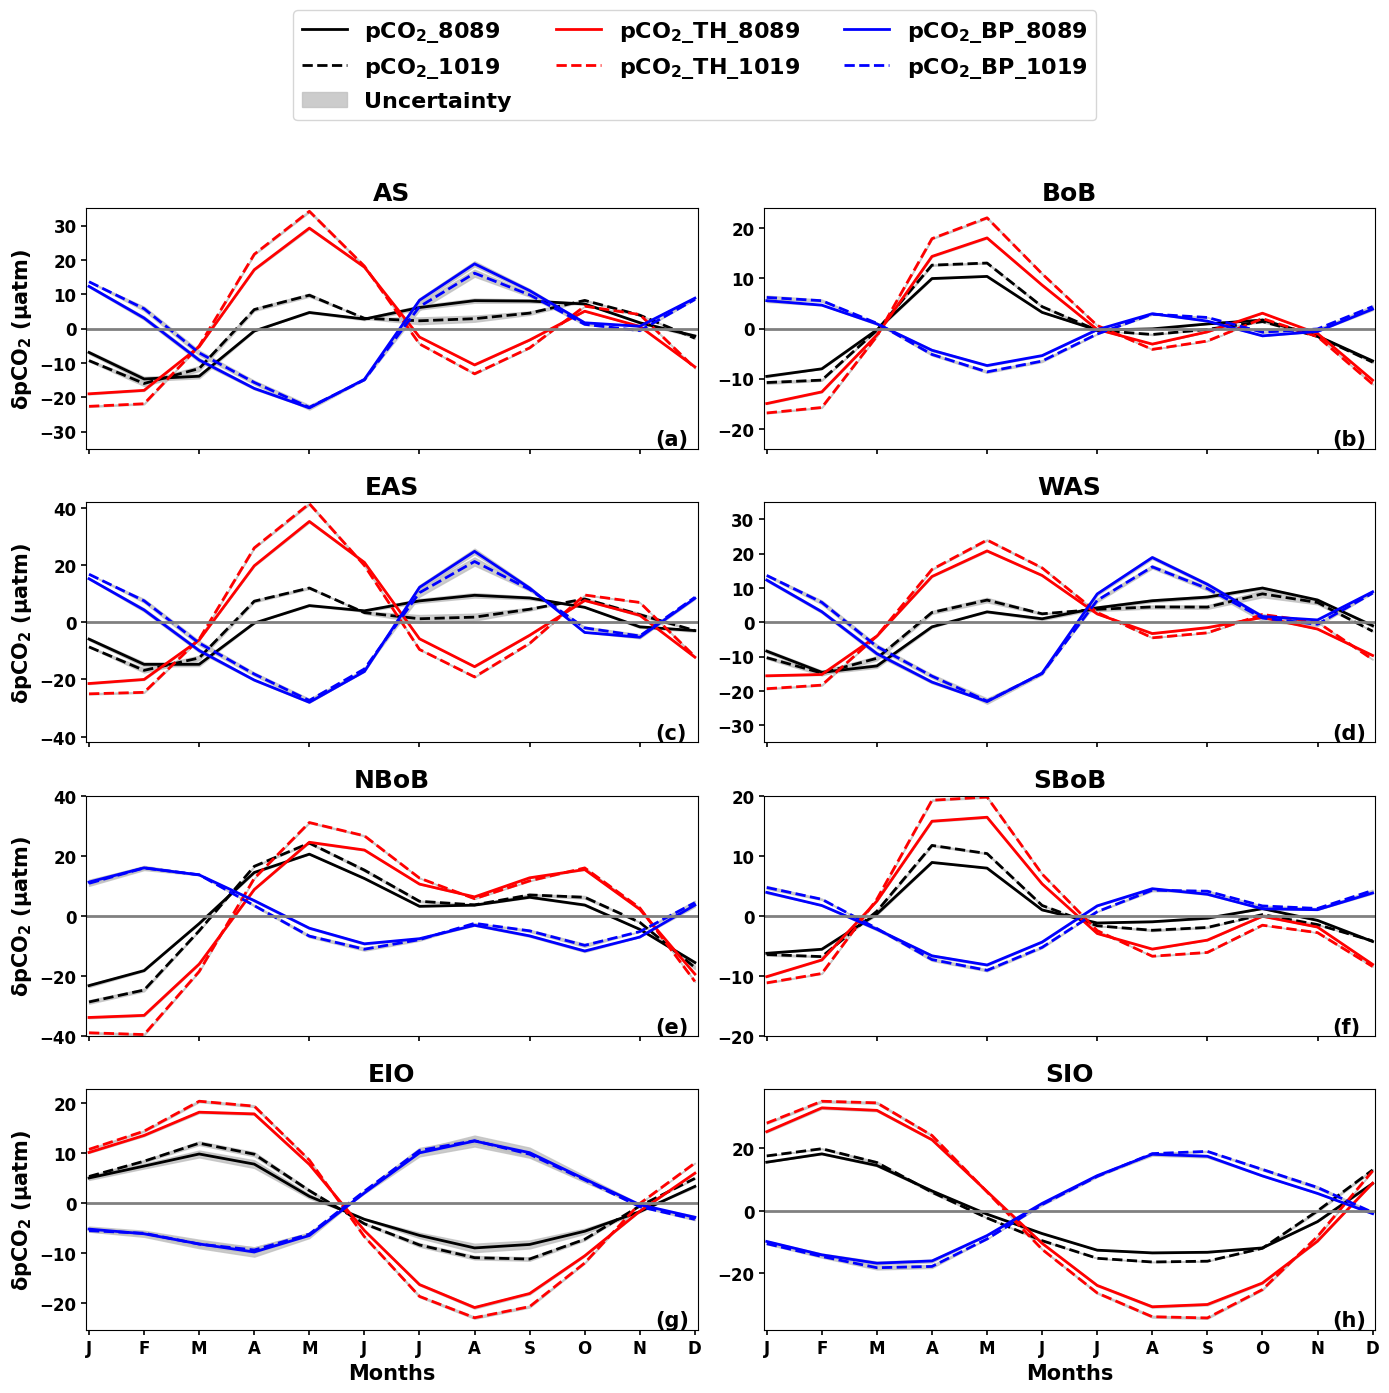

In [190]:
fig, axes = plt.subplots(4, 2, figsize=(14, 14))
axes = axes.ravel()

# Region information for looping
regions = [
    (
        "AS",  
        sea_AS_8089, dev_sea_AS_8089,
        sea_AS_1019, dev_sea_AS_1019,
        sea_AS_thermal_8089, dev_sea_AS_thermal_8089, 
        sea_AS_thermal_1019, dev_sea_AS_thermal_8089,
        sea_AS_bp_8089, dev_sea_AS_bp_8089,
        sea_AS_bp_1019, dev_sea_AS_bp_1019,
        (-35, 35)
    ),
    (
        "BoB",  
        sea_BoB_8089, dev_sea_BoB_8089,
        sea_BoB_1019, dev_sea_BoB_1019,
        sea_BoB_thermal_8089, dev_sea_BoB_thermal_8089, 
        sea_BoB_thermal_1019, dev_sea_BoB_thermal_8089,
        sea_BoB_bp_8089, dev_sea_BoB_bp_8089,
        sea_BoB_bp_1019, dev_sea_BoB_bp_1019,
        (-24, 24)
    ),
    (
        "EAS",  
        sea_EAS_8089, dev_sea_EAS_8089,
        sea_EAS_1019, dev_sea_EAS_1019,
        sea_EAS_thermal_8089, dev_sea_EAS_thermal_8089, 
        sea_EAS_thermal_1019, dev_sea_EAS_thermal_8089,
        sea_EAS_bp_8089, dev_sea_EAS_bp_8089,
        sea_EAS_bp_1019, dev_sea_EAS_bp_1019,
        (-42, 42)
    ),
    (
        "WAS",  
        sea_WAS_8089, dev_sea_WAS_8089,
        sea_WAS_1019, dev_sea_WAS_1019,
        sea_WAS_thermal_8089, dev_sea_WAS_thermal_8089, 
        sea_WAS_thermal_1019, dev_sea_WAS_thermal_8089,
        sea_WAS_bp_8089, dev_sea_WAS_bp_8089,
        sea_WAS_bp_1019, dev_sea_WAS_bp_1019,
        (-35, 35)
    ),
    (
        "NBoB",  
        sea_NBoB_8089, dev_sea_NBoB_8089,
        sea_NBoB_1019, dev_sea_NBoB_1019,
        sea_NBoB_thermal_8089, dev_sea_NBoB_thermal_8089, 
        sea_NBoB_thermal_1019, dev_sea_NBoB_thermal_8089,
        sea_NBoB_bp_8089, dev_sea_NBoB_bp_8089,
        sea_NBoB_bp_1019, dev_sea_NBoB_bp_1019,
        (-40,40)
    ),
    (
        "SBoB",  
        sea_SBoB_8089, dev_sea_SBoB_8089,
        sea_SBoB_1019, dev_sea_SBoB_1019,
        sea_SBoB_thermal_8089, dev_sea_SBoB_thermal_8089, 
        sea_SBoB_thermal_1019, dev_sea_SBoB_thermal_8089,
        sea_SBoB_bp_8089, dev_sea_SBoB_bp_8089,
        sea_SBoB_bp_1019, dev_sea_SBoB_bp_1019,
        (-20,20)
    ),
    (
        "EIO", 
        sea_EIO_8089, dev_sea_EIO_8089,
        sea_EIO_1019, dev_sea_EIO_1019,
        sea_EIO_thermal_8089, dev_sea_EIO_thermal_8089, 
        sea_EIO_thermal_1019, dev_sea_EIO_thermal_8089,
        sea_EIO_bp_8089, dev_sea_EIO_bp_8089,
        sea_EIO_bp_1019, dev_sea_EIO_bp_1019,
        (None, None)
    ),
    (
        "SIO", 
        sea_SIO_8089, dev_sea_SIO_8089,
        sea_SIO_1019, dev_sea_SIO_1019,
        sea_SIO_thermal_8089, dev_sea_SIO_thermal_8089, 
        sea_SIO_thermal_1019, dev_sea_SIO_thermal_8089,
        sea_SIO_bp_8089, dev_sea_SIO_bp_8089,
        sea_SIO_bp_1019, dev_sea_SIO_bp_1019,
        (None, None)
    ),
]

for i, (
    title,
    amp_8089, dev_8089,
    amp_1019, dev_1019,
    amp_th_8089, dev_th_8089,
    amp_th_1019, dev_th_1019,
    amp_bp_8089, dev_bp_8089,
    amp_bp_1019, dev_bp_1019,
    ylim,
) in enumerate(regions):
    ax = axes[i]
    ax.margins(x=0)

    # Plot amplitude + error shading
    ax.plot(Month, amp_8089, "k-", linewidth=2, label=r"pCO$\mathbf{_2}$_8089")
    ax.fill_between(Month, amp_8089 - dev_8089, amp_8089 + dev_8089, color="silver", alpha=0.8)
    ax.plot(Month, amp_1019, "k--", linewidth=2, label=r"pCO$\mathbf{_2}$_1019")
    ax.fill_between(Month, amp_1019 - dev_1019, amp_1019 + dev_1019, color="silver", alpha=0.8, label="Uncertainty")
    ax.plot(Month, amp_th_8089, "r-", linewidth=2, label=r"pCO$\mathbf{_2}$_TH_8089")
    ax.fill_between(Month, amp_th_8089 - dev_th_8089, amp_th_8089 + dev_th_8089, color="silver", alpha=0.8)
    ax.plot(Month, amp_th_1019, "r--", linewidth=2, label=r"pCO$\mathbf{_2}$_TH_1019")
    ax.fill_between(Month, amp_th_1019 - dev_th_1019, amp_th_1019 + dev_th_1019, color="silver", alpha=0.8)
    ax.plot(Month, amp_bp_8089, "b-", linewidth=2, label=r"pCO$\mathbf{_2}$_BP_8089")
    ax.fill_between(Month, amp_bp_8089 - dev_bp_8089, amp_bp_8089 + dev_bp_8089, color="silver", alpha=0.8)
    ax.plot(Month, amp_bp_1019, "b--", linewidth=2, label=r"pCO$\mathbf{_2}$_BP_1019")    
    ax.fill_between(Month, amp_bp_1019 - dev_bp_1019, amp_bp_1019 + dev_bp_1019, color="silver", alpha=0.8)
    # ax.fill_between(years, amp - err, amp + err, color="silver", alpha=0.6, label="Uncertainty")
   
    # 🔥 Add horizontal reference line at y=0
    ax.axhline(0, color="gray", linestyle="-", linewidth=2)
    
    # Trend line
    # ax.plot(years, intercept + slope * years, "m--", label="Trend")

    # Titles and limits
    ax.set_title(title, fontsize=18, fontweight="bold")
    ax.set_xlim([-0.05, 11.05])
    if ylim[0] is not None:
        ax.set_ylim(ylim)

    # Add trend annotation (inside each subplot)
    # ax.text(
    #     0.05, 0.05,
    #     f"Trend = {slope:.2f} ± {slope_err:.2f} µatm/yr (p<0.1)",
    #     transform=ax.transAxes,
    #     fontsize=12,
    #     fontweight="bold",
    #     va="top",
    #     ha="left",
    #     c="k"
    # )

    # Subplot labels (a), (b), (c), (d)
    ax.text(0.93, 0.08, f"({chr(ord('a') + i)})",
            transform=ax.transAxes,
            fontsize=15, fontweight="bold", va="top")

    # Axis labels
    if i in [6, 7]:  # bottom row
        ax.set_xticklabels(Month_lbl, fontweight="bold")
        ax.set_xlabel("Months", fontsize=15, fontweight="bold")
        # ax.set_xticklabels(Month_lbl)
        ax.set_xticks(Month)
    else:
        ax.set_xticklabels([])  # hide xtick labels for top row
        
    if i in [0, 2,4,6]:  # left column
        ax.set_ylabel(r"$\mathbf{\delta pCO_{2}}$ (µatm)", fontsize=15, fontweight="bold")

    ax.tick_params(axis="both", labelsize=12, width=1.2)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")

legend_font = FontProperties(weight="bold", size=16)
# Add legend only once, below all subplots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3,  prop=legend_font)

plt.tight_layout(rect=[0, 0, 1, 0.88])  # leave space for legend
# plt.savefig('seasonal_amp_more.png', dpi=500, bbox_inches='tight', facecolor='white')
plt.show()


/tmp/ipykernel_849405/4027746829.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(Month_lbl, fontweight="bold")
/tmp/ipykernel_849405/4027746829.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(Month_lbl, fontweight="bold")


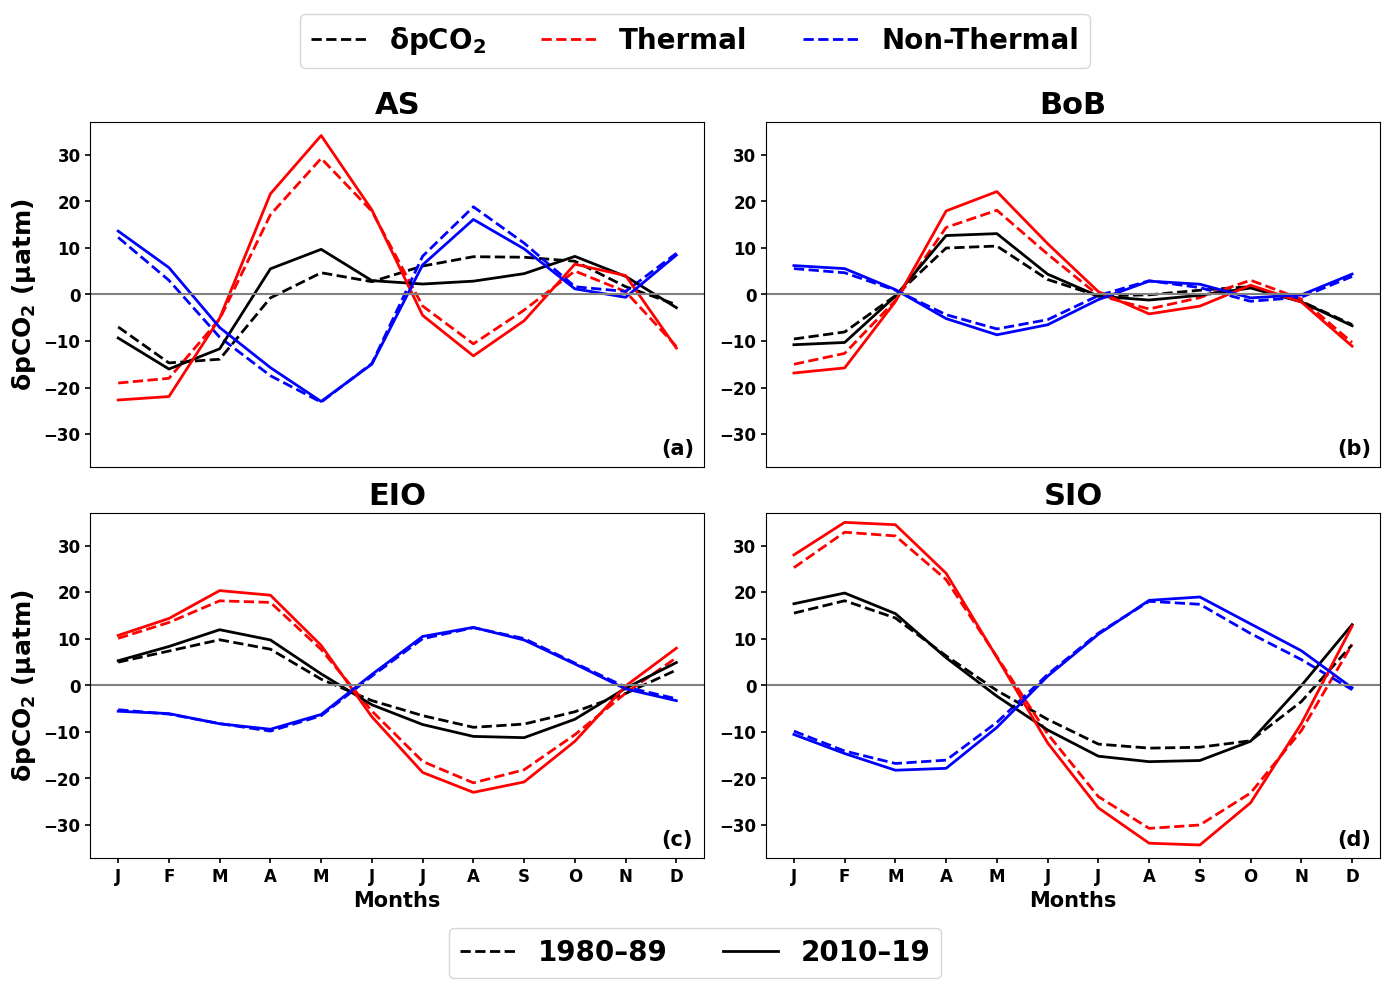

In [197]:
import matplotlib.pyplot as plt
import calendar
from matplotlib.lines import Line2D
from matplotlib.font_manager import FontProperties

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

regions = ["AS", "BoB", "EIO", "SIO"]

# Colors for components
colors = {
    "total": "k",
    "thermal": "r",
    "bp": "b"
}

# Flexible y-limits (None = auto)
ylims = {
    "AS": (-37, 37),
    "BoB": (-37, 37),
    "EIO": (-37, 37),
    "SIO": (-37, 37)
}

for i, (ax, region) in enumerate(zip(axes, regions)):

    # === 1980–89 (dashed lines) ===
    globals()[f"sea_{region}_8089"].plot(ax=ax, c=colors["total"], linestyle="--", 
                                         label="Total (1980–89)", linewidth=2)
    globals()[f"sea_{region}_thermal_8089"].plot(ax=ax, c=colors["thermal"], linestyle="--", 
                                                 label="Thermal (1980–89)", linewidth=2)
    globals()[f"sea_{region}_bp_8089"].plot(ax=ax, c=colors["bp"], linestyle="--", 
                                            label="Biological (1980–89)", linewidth=2)

    # === 2010–19 (solid lines) ===
    globals()[f"sea_{region}_1019"].plot(ax=ax, c=colors["total"], linestyle="-", 
                                         label="Total (2010–19)", linewidth=2)
    globals()[f"sea_{region}_thermal_1019"].plot(ax=ax, c=colors["thermal"], linestyle="-", 
                                                 label="Thermal (2010–19)", linewidth=2)
    globals()[f"sea_{region}_bp_1019"].plot(ax=ax, c=colors["bp"], linestyle="-", 
                                            label="Biological (2010–19)", linewidth=2)

    # Title
    ax.set_title(region, fontsize=22, fontweight="bold")

    # Horizontal reference line
    ax.axhline(0, color="gray", linestyle="-", linewidth=1.5)

    # Y-axis label
    if i in [0, 2]:
        ax.set_ylabel(r"$\mathbf{\delta pCO_{2}}$ (µatm)", fontsize=18, fontweight="bold")

    # Apply y-limits if specified
    if ylims[region] is not None:
        ax.set_ylim(ylims[region])

    # # Axis labels
    # if i in [6, 7]:  # bottom row
    #     ax.set_xticklabels(Month_lbl, fontweight="bold")
    #     ax.set_xlabel("Months", fontsize=15, fontweight="bold")
    #     # ax.set_xticklabels(Month_lbl)
    #     ax.set_xticks(Month)
    # else:
    #     ax.set_xticklabels([])  # hide xtick labels for top row

    # X-axis labels
    if i in [2, 3]:  # bottom row 
        ax.set_xticklabels(Month_lbl, fontweight="bold")
        ax.set_xlabel("Months",fontsize=15,fontweight="bold")
        ax.set_xticks(np.arange(1,13,1))
    else:  # top row
        ax.set_xticks([])
        ax.set_xticklabels([])
        ax.set_xlabel("")

    # Subplot labels (a, b, c, d)
    ax.text(0.93, 0.08, f"({chr(ord('a') + i)})",
            transform=ax.transAxes,
            fontsize=15, fontweight="bold", va="top")

    # Ticks styling
    ax.tick_params(axis="both", labelsize=12, width=1.2)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")

# === Legends ===
legend_font = FontProperties(weight="bold", size=20)  # bigger font

# Top legend: Total, Thermal, Biological
lines, labels = axes[0].get_legend_handles_labels()
top_labels = ["$\mathbf{\delta pCO_{2}}$", "Thermal", "Non-Thermal"]
fig.legend(lines[:3], top_labels, loc="upper center", ncol=3, prop=legend_font)

# Bottom legend: decades
legend_lines = [
    Line2D([0], [0], color="k", linestyle="--", lw=2, label="1980–89"),
    Line2D([0], [0], color="k", linestyle="-", lw=2, label="2010–19"),
]
fig.legend(handles=legend_lines, loc="lower center", ncol=2, prop=legend_font)

plt.tight_layout(rect=[0, 0.07, 1, 0.92])
# plt.savefig('seasonal_amp.png', dpi=800, bbox_inches='tight', facecolor='white')

plt.show()
